In [1]:
import xarray as xr
import geopandas as gpd
import avalanchers as ava
# load shape file
id = 10
gdf = gpd.read_file(f"data/single_avalanche_outlines_switzerland_2018/polygon_{id}.shp")

easting = gdf.geometry.centroid.x
northing = gdf.geometry.centroid.y

# estimate slab height
start_day = 20
end_day = 24
snow = xr.open_dataset("data/OSHD_DATA_2018-01.nc")
diff = snow.sel(time=f"2018-01-{end_day}T07:00:00")  - snow.sel(time=f"2018-01-{start_day}T07:00:00")
slab_height = diff.interp(easting=easting, northing=northing, method="linear")
swe_diff = diff.interp(easting=easting, northing=northing, method="linear")
slab_height
density_water = 1000  # kg/m^3
# density = ((swe_diff / slab_height).values()) * density_water
density=1
print(f"end={end_day}, start={start_day}, slab_height={slab_height.values} m, swe_diff={swe_diff.values} m, density={density} kg/m^3")


DataSourceError: data/single_avalanche_outlines_switzerland_2018/polygon_10.shp: No such file or directory

In [3]:
diff = snow.sel(time=f"2018-01-{end_day}T07:00:00") - snow.sel(time=f"2018-01-{start_day}T07:00:00")

slab_height = diff.hs.interp(easting=easting, northing=northing, method="linear")[0][0]
swe_diff = diff.swe.interp(easting=easting, northing=northing, method="linear")[0][0]
rho_new = swe_diff / slab_height  # already kg/m³
print(f"end={end_day}, start={start_day}, new_snow={slab_height:.2f} m, swe_diff={swe_diff:.2f} kg/m², density={rho_new:.2f} kg/m³, slab_height_200={swe_diff/200:.2f} m")


end=24, start=20, new_snow=0.15 m, swe_diff=76.19 kg/m², density=515.69 kg/m³, slab_height_200=0.38 m


In [ ]:
xr.open_dataset("data/OSHD_DATA_2018-01.nc")

GENERAL [Loader Message (0x0)]
	windows_read_data_files_in_registry: Registry lookup failed to get layer manifest files.
	objects: (type: INSTANCE, hndl: 0x28ec966a9e0, name: ?)


Evaluation(jaccard=0.8706, alpha=0.8706, beta=0.0607, gamma=0.0687, beeline_distance_3d=1021.85, chamfer=0.001998, iou=0.8701, beeline_3d=1021.85, beeline_3d_ref=763.87, peak_velocity=20.94)
Loss
Velocity loss: 0.000, peak_velocity: 20.9 m/s, v_max_physical: 63.4 m/s
Runout loss: 0.338 (absolute: 258 m)
Area loss: 0.130


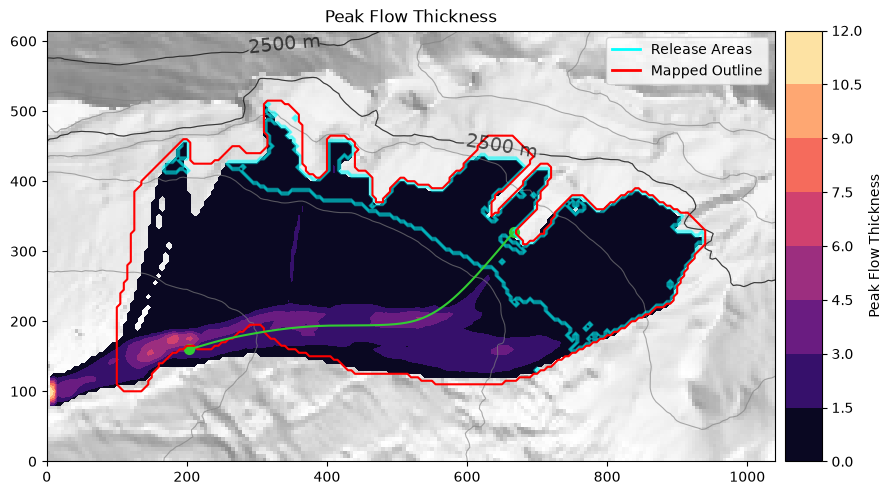

In [1]:
import numpy as np
import avalanchers
import matplotlib.pyplot as plt
example_case = "avaWog"
settings = {
    # mandatory: path to the DEM, currently only custom encoded png files are supported
    # optional, if not provided, a simple algorithm will be used to determine release areas based on the DEM
    # "dem_path": f"data/avaframe/{example_case}.png",
    # "release_areas_path": f"data/avaframe/{example_case}releaseTexture.png",   
    # "dem_path": f"data/stubai/10DTM_pilotStubai.tif", 
    # "release_areas_path": f"data/stubai/stubai_release_areas.png",
    # "dem_path": f"data/vals/PAR6_Vals_Gries_dtm_10_utm32n_bil_.tif",
    # "release_areas_path": f"data/vals/release.tif", 
    "outlines_path": "data/single_avalanche_outlines_switzerland_2018/polygon_10720.shp",  
    "outlines_padding": 100,
    
    "max_steps": 5000,
    "batch_compute_steps": 300,
    "sim_model": "mpm",
    "released_particles_per_cell": 4,
    "friction_model": "voellmy",
    "density": 200.0,
    "slab_thickness_factor": 0.5,
    "friction_coefficient": 0.2,
    "drag_coefficient": 2000.0,
    "cfl": 0.5,
    "min_slope_angle": 28.0,
    "max_slope_angle": 50.0,
    "release_min_elevation": 2461.0,
    "velocity_threshold": 0.1,
    "roughness_threshold": 0.01,
    "enable_curvature": True,
    "enable_particle_interaction": True,
    "enable_entrainment": True,
}
sim = avalanchers.PySimulation.new()
sim.create(settings)
settings['release_min_elevation'] = float(np.percentile(sim.dem[sim.roi], 60))
sim.create(settings)
sim.run()
sim.post_process()
evaluation = sim.evaluate()

fig, ax, _, _ = avalanchers.plot2d(sim, parameter="peak_flow_thickness", title="Peak Flow Thickness", threshold_value=0.01, particles=False, roi=True)
print(evaluation)

# energy conversion efficiency eta: 0.65 - 0.85, v_max = eta * sqrt(2 * g * vertical_drop)
v_max_physical = max(0.75 * np.sqrt(2 * 9.81 * evaluation["vertical_drop"]), 40)  # assuming eta = 0.75 as an example
v_min = 15
loss_velocity = (max(0, v_min - evaluation["peak_velocity"]) / v_min)**2 + (max(0, evaluation["peak_velocity"] - v_max_physical) / v_max_physical)**2
loss_runout = abs(evaluation["beeline_3d"] - evaluation["beeline_3d_ref"]) / evaluation["beeline_3d_ref"]
print("Loss")
print(f"Velocity loss: {loss_velocity:.3f}, peak_velocity: {evaluation['peak_velocity']:.1f} m/s, v_max_physical: {v_max_physical:.1f} m/s")
print(f"Runout loss: {loss_runout:.3f} (absolute: {abs(evaluation['beeline_3d'] - evaluation['beeline_3d_ref']):.0f} m)")
# print(f"Chamfer loss: {compute_chamfer_loss(sim.peak_flow_thickness, sim.roi, h_thresh=0.01) * sim.cell_size / evaluation['beeline_3d_ref']:.4f}")
print(f"Area loss: {1 - evaluation['iou']:.3f}")
ax.plot(sim.center_of_mass_x[:-1], sim.center_of_mass_y[:-1], color="limegreen")
ax.scatter(sim.center_of_mass_x[-2], sim.center_of_mass_y[-2], color="limegreen", s=50)
ax.scatter(sim.center_of_mass_x[0], sim.center_of_mass_y[0], color="limegreen", s=50)


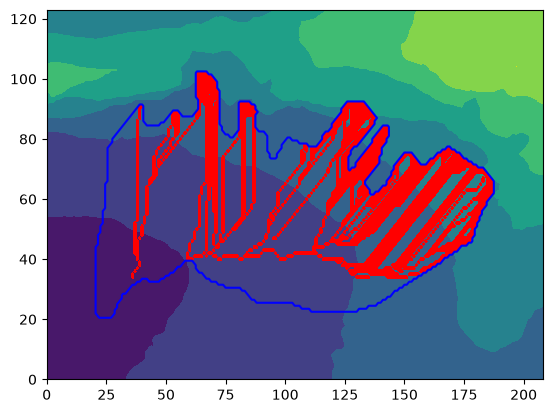

In [7]:
import numpy as np

def extract_release_zone(
    dem: np.ndarray, 
    avalanche_mask: np.ndarray, 
    fraction: float = 0.25, 
    cell_size: float = 1.0
) -> np.ndarray:
    """
    Detects crown line at upper boundary and fills downslope release area.
    Prevents runout/bottom boundary detection using internal flow direction & elevation filtering.
    """
    rows, cols = dem.shape
    mask = (avalanche_mask > 0)
    
    if not np.any(mask):
        return np.zeros_like(dem, dtype=np.uint8)

    # 8-neighbor offsets [NW, N, NE, W, E, SW, S, SE]
    dr = np.array([-1, -1, -1,  0, 0,  1, 1, 1])
    dc = np.array([-1,  0,  1, -1, 1, -1, 0, 1])
    step_dists = np.array([np.sqrt(2), 1.0, np.sqrt(2), 1.0, 1.0, np.sqrt(2), 1.0, np.sqrt(2)]) * cell_size

    dem_padded = np.pad(dem, 1, mode='edge')
    mask_padded = np.pad(mask, 1, mode='constant', constant_values=False)

    # 1. Compute D8 Flow Direction across DEM
    slopes = np.full((8, rows, cols), -np.inf)
    for i in range(8):
        r_shift, c_shift = 1 + dr[i], 1 + dc[i]
        neighbor_dem = dem_padded[r_shift:r_shift+rows, c_shift:c_shift+cols]
        slopes[i] = (dem - neighbor_dem) / step_dists[i]

    max_slope_idx = np.argmax(slopes, axis=0)
    max_slope_val = np.max(slopes, axis=0)
    fdir = np.where(max_slope_val > 0, max_slope_idx, -1)  # -1 for sinks/flats

    # 2. Identify Perimeter Boundary Cells (Inside mask, touching outside)
    is_boundary = np.zeros((rows, cols), dtype=bool)
    for i in range(8):
        r_nbr, c_nbr = 1 + dr[i], 1 + dc[i]
        nbr_mask = mask_padded[r_nbr:r_nbr+rows, c_nbr:c_nbr+cols]
        is_boundary |= (mask & (~nbr_mask))

    # 3. Detect Crown Line (Upslope Boundary ONLY)
    # FIX: Check if cell's OWN flow direction points INTO the avalanche polygon interior.
    # Bottom/runout boundary cells flow OUT of the polygon, so mask[nr, nc] is False.
    flows_into_mask = np.zeros((rows, cols), dtype=bool)
    boundary_coords = np.argwhere(is_boundary)
    
    for r, c in boundary_coords:
        direction = fdir[r, c]
        if direction != -1:
            nr, nc = r + dr[direction], c + dc[direction]
            if 0 <= nr < rows and 0 <= nc < cols and mask[nr, nc]:
                flows_into_mask[r, c] = True

    crown_candidates = is_boundary & flows_into_mask

    # FIX: Filter out lower flanks (keep upper 50% elevation of candidate boundary cells)
    if np.any(crown_candidates):
        cand_elevs = dem[crown_candidates]
        elev_cutoff = np.percentile(cand_elevs, 50)
        crown_mask = crown_candidates & (dem >= elev_cutoff)
    else:
        # Fallback if ridge/flat top: take highest 15% boundary cells
        poly_elevs = dem[mask]
        top_elev = np.percentile(poly_elevs, 85)
        crown_mask = is_boundary & (dem >= top_elev)

    # 4. Compute Downslope Distance from Crown Line
    dist_map = np.full((rows, cols), np.inf)
    dist_map[crown_mask] = 0.0

    mask_coords = np.argwhere(mask)
    elevations = dem[mask_coords[:, 0], mask_coords[:, 1]]
    sorted_indices = mask_coords[np.argsort(-elevations)]  # High-to-low elevation traversal

    for r, c in sorted_indices:
        d_curr = dist_map[r, c]
        if np.isinf(d_curr):
            continue

        direction = fdir[r, c]
        if direction != -1:
            nr, nc = r + dr[direction], c + dc[direction]
            if 0 <= nr < rows and 0 <= nc < cols and mask[nr, nc]:
                new_dist = d_curr + step_dists[direction]
                if new_dist < dist_map[nr, nc]:
                    dist_map[nr, nc] = new_dist
        else:
            # Handle local flats/sinks inside polygon
            for i in range(8):
                nr, nc = r + dr[i], c + dc[i]
                if 0 <= nr < rows and 0 <= nc < cols and mask[nr, nc]:
                    if dem[nr, nc] <= dem[r, c]:
                        new_dist = d_curr + step_dists[i]
                        if new_dist < dist_map[nr, nc]:
                            dist_map[nr, nc] = new_dist

    # 5. Fill Exact 20-30% Area Downward
    valid_mask = mask & np.isfinite(dist_map)
    valid_dists = dist_map[valid_mask]

    if len(valid_dists) == 0:
        return np.zeros_like(dem, dtype=np.uint8)

    target_cell_count = int(np.round(np.sum(mask) * fraction))
    target_cell_count = max(1, min(target_cell_count, len(valid_dists)))

    # Find distance threshold for exact cell count
    cutoff_dist = np.partition(valid_dists, target_cell_count - 1)[target_cell_count - 1]
    release_mask = mask & (dist_map <= cutoff_dist)

    return release_mask.astype(np.uint8)

r = extract_release_zone(sim.dem, sim.roi, cell_size=5.0, fraction=0.5)
plt.contourf(sim.dem)
plt.contourf(r, colors='red', levels=[0.5, 4])
plt.contour(sim.roi, colors='blue')
plt.show()

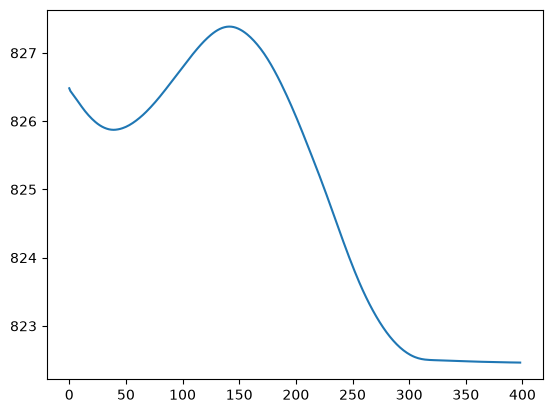

In [10]:
plt.plot(sim.center_of_mass[0][:-1])

In [13]:
sim.center_of_mass[0][-3:]

array([822.4634 , 822.46295,   0.     ], dtype=float32)

In [3]:
import numpy as np
from scipy.ndimage import distance_transform_edt

def compute_chamfer_loss(
    peak_flow_thickness: np.ndarray,
    reference_mask: np.ndarray,
    h_thresh: float = 0.01
) -> float:
    """
    Computes symmetric, normalized Chamfer distance loss between a simulated 
    peak flow thickness grid and a mapped reference outline.

    Parameters
    ----------
    peak_flow_thickness : np.ndarray (2D float)
        Simulated peak flow thickness array (h_max).
    reference_mask : np.ndarray (2D bool or int)
        Binary array of observed avalanche footprint (1 inside, 0 outside).
    h_thresh : float
        Thickness threshold to define the simulated footprint boundary.

    Returns
    -------
    float
        Symmetric normalized Chamfer distance in grid cell units.
    """
    # 1. Threshold flow depth to build binary simulation mask
    sim_mask = (peak_flow_thickness >= h_thresh).astype(bool)
    obs_mask = reference_mask.astype(bool)

    # Count active cells for normalization
    n_sim = np.count_nonzero(sim_mask)
    n_obs = np.count_nonzero(obs_mask)

    # Handle edge cases where either mask is completely empty
    if n_sim == 0 or n_obs == 0:
        return 1e6  # Large penalty penalty for failed/empty simulations

    # Exact match optimization
    if np.array_equal(sim_mask, obs_mask):
        return 0.0

    # 2. Compute Euclidean Distance Transforms (EDT)
    # distance_transform_edt calculates distance from zero cells to nearest non-zero cell.
    # We invert (~mask) so it measures distance to the footprint mask.
    edt_obs = distance_transform_edt(~obs_mask)
    edt_sim = distance_transform_edt(~sim_mask)

    # 3. Direction 1: Sim -> Obs (Sum distances of sim cells to nearest obs cell)
    dist_sim_to_obs = edt_obs[sim_mask].sum() / n_sim

    # 4. Direction 2: Obs -> Sim (Sum distances of obs cells to nearest sim cell)
    dist_obs_to_sim = edt_sim[obs_mask].sum() / n_obs

    # 5. Symmetric Chamfer Loss
    chamfer_loss = float(dist_sim_to_obs + dist_obs_to_sim)

    return chamfer_loss


# ==========================================
# Example Usage & Verification
# ==========================================
if __name__ == "__main__":
    grid_shape = (200, 200)

    # Generate dummy reference mask (e.g., box footprint)
    reference = np.zeros(grid_shape, dtype=int)
    reference[50:120, 80:120] = 1

    # Case A: Perfectly aligned simulation
    sim_perfect = np.zeros(grid_shape, dtype=float)
    sim_perfect[50:120, 80:120] = 0.5  # > h_thresh
    print(f"Perfect Match Loss: {compute_chamfer_loss(sim_perfect, reference):.4f}")

    # Case B: Slightly shifted/expanded simulation
    sim_shifted = np.zeros(grid_shape, dtype=float)
    sim_shifted[55:125, 85:125] = 0.5
    print(f"Shifted Match Loss: {compute_chamfer_loss(sim_shifted, reference):.4f}")

    # Case C: Collapsed simulation (very small)
    sim_collapsed = np.zeros(grid_shape, dtype=float)
    sim_collapsed[50:52, 80:82] = 0.5
    print(f"Collapsed Sim Loss: {compute_chamfer_loss(sim_collapsed, reference):.4f}")

Perfect Match Loss: 0.0000
Shifted Match Loss: 1.1513
Collapsed Sim Loss: 41.1303


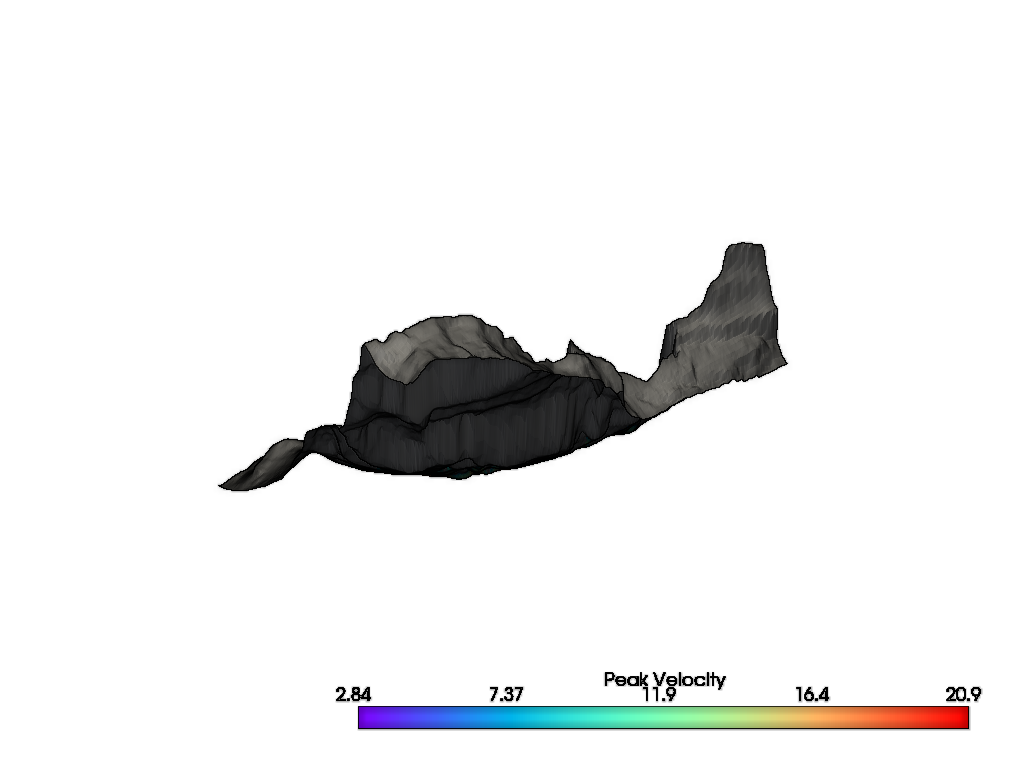

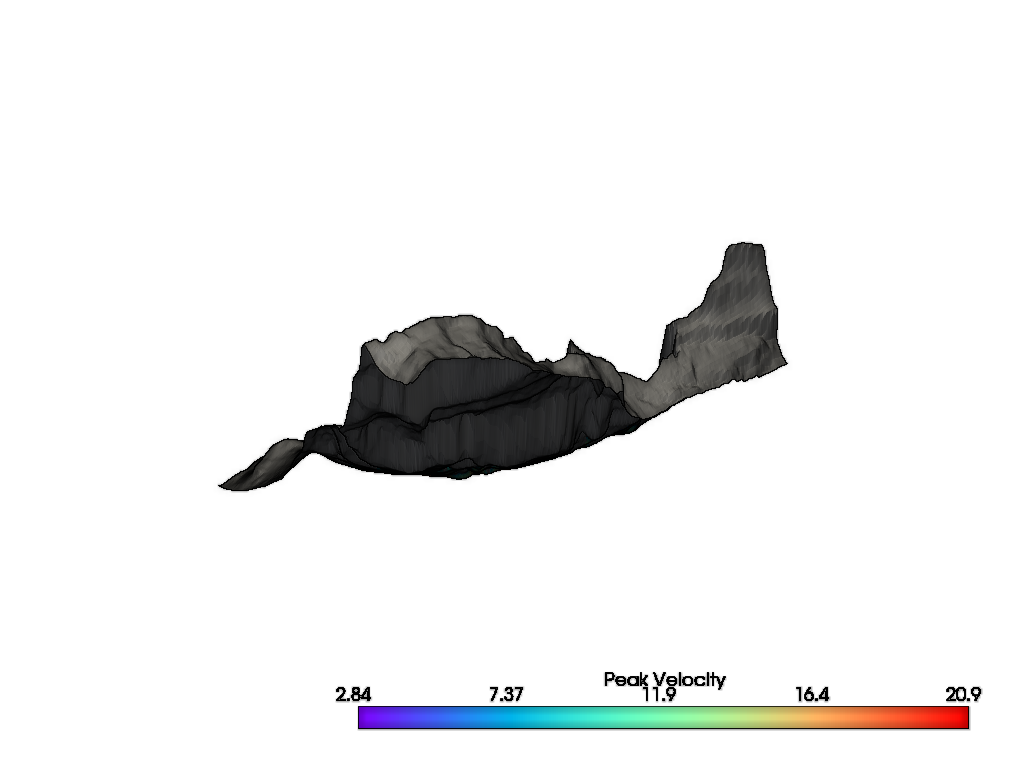

In [10]:

await avalanchers.setup_jupyter_3d()
avalanchers.plot3d(sim, "peak_velocity")

In [ ]:
import cma
import numpy as np

turbulent_coefficient_scale = 4000

# Your simulation
def run_simulation(param1, param2):
    # ... run model ...
    score = ...  # returns between -1 and 1
    return score

# CMA-ES objective (must minimize)
def objective(x):
    mu, xi = decode_parameters(x)
    score = run_simulation(mu, xi)

    # Convert maximization to minimization
    return 1 - score

def decode_parameters(x):
    mu = x[0]
    log10_xi = x[1]
    xi = 10 ** log10_xi
    return mu, xi

# Initial guess, µ, eta scaled with log
x0 = [0.25, np.log10(2000)]

# Initial search radius
sigma0 = 0.1

es = cma.CMAEvolutionStrategy(
    x0,
    sigma0,
    {
        "maxfevals": 200,
        # "bounds": [[0.05, 0.60], [200.0, 5000.0]],  # broad
        "bounds": [[0.1, np.log10(500.0)], [0.45, np.log10(3500.0)]],  # see https://ramms.ch/wp-content/uploads/RAMMS_MuXi_Table.pdf
        "verb_disp": 1,
    },
)

while not es.stop():
    solutions = es.ask()
    fitnesses = [objective(x) for x in solutions]
    es.tell(solutions, fitnesses)
    es.disp()

print("Best parameters:", es.result.xbest)
print("Best score:", -es.result.fbest)

<xarray.DataArray 'hs' ()> Size: 8B
array(0.36525)
Coordinates:
    easting   int64 8B 2640000
    northing  int64 8B 1160000
Attributes:
    unit:           m
    standard_name:  surface_snow_thickness
    long_name:      Snow depth
    content_type:   modelResult

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal, Categorical, MixtureSameFamily, Independent
import cma

# Set seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# =====================================================================
# STAGE 1: Forward Simulation Engine & CMA-ES Calibration
# =====================================================================

class VoellmySimulator:
    """
    Mock wrapper for a 2D Voellmy Avalanche Solver (e.g., RAMMS, AvaFrame).
    Calculates runout extent based on Coulomb friction (mu) and turbulent friction (xi).
    """
    def __init__(self, observation_mask: np.ndarray):
        self.obs_mask = observation_mask  # 2D Binary array (1 = observed extent)

    def run_simulation(self, mu: float, xi: float) -> np.ndarray:
        """
        Simulate avalanche extent given parameters (mu, xi).
        Replace this mock with actual CLI/Python call to your solver.
        """
        # Mock physics: Higher mu/xi reduces runout length along rows
        rows, cols = self.obs_mask.shape
        sim_mask = np.zeros_like(self.obs_mask)
        
        # Simple thresholding trick simulating runout length
        max_row = int(rows * (1.0 - (0.4 * mu + 0.0001 * xi)))
        max_row = np.clip(max_row, 5, rows)
        sim_mask[:max_row, :] = 1
        return sim_mask


def loss_iou(sim_mask: np.ndarray, obs_mask: np.ndarray) -> float:
    """Computes Jaccard Loss (1 - IoU) for Extent Overlap."""
    intersection = np.logical_and(sim_mask, obs_mask).sum()
    union = np.logical_or(sim_mask, obs_mask).sum()
    if union == 0:
        return 1.0
    return 1.0 - (intersection / union)


def calibrate_event_cmaes(simulator: VoellmySimulator) -> np.ndarray:
    """
    Calibrates (mu, xi) for a single avalanche event using CMA-ES.
    Parameters are normalized to [0, 1] internally for numerical stability.
    """
    # Parameter Bounds: mu in [0.05, 0.40], xi in [100, 3000]
    bounds_min = np.array([0.05, 100.0])
    bounds_max = np.array([0.40, 3000.0])

    def unnormalize(norm_params):
        return bounds_min + norm_params * (bounds_max - bounds_min)

    def objective(norm_params):
        # Enforce hard bounds
        if np.any(norm_params < 0) or np.any(norm_params > 1):
            return 1e6
        
        mu, xi = unnormalize(norm_params)
        sim_mask = simulator.run_simulation(mu, xi)
        return loss_iou(sim_mask, simulator.obs_mask)

    # Initial guess in normalized space [0.5, 0.5] with initial std 0.2
    x0 = [0.5, 0.5]
    opts = {'popsize': 12, 'bounds': [0, 1], 'verbose': -9, 'maxiter': 30}
    
    es = cma.CMAEvolutionStrategy(x0, 0.2, opts)
    es.optimize(objective)
    
    best_norm = es.result.xbest
    return unnormalize(best_norm)


# =====================================================================
# STAGE 2: Dataset Generation (Mock Synthetic Events)
# =====================================================================

def generate_synthetic_dataset(num_events: int = 150):
    """Generates synthetic terrain features and calibrates parameters via CMA-ES."""
    features = []  # [Release Volume (m3), Mean Slope (deg), Elevation (m)]
    targets = []   # Calibrated [mu, xi]

    print(f"Calibrating {num_events} avalanche events using CMA-ES...")
    for i in range(num_events):
        # 1. Generate random terrain features
        volume = np.random.uniform(1000, 50000)
        slope = np.random.uniform(28, 45)
        elevation = np.random.uniform(1500, 3500)
        
        # Mock ground truth observation mask
        mock_grid = np.zeros((50, 50))
        target_length = int(50 * (volume / 50000.0) * (slope / 45.0))
        mock_grid[:max(10, target_length), :] = 1
        
        # 2. Calibrate parameters using CMA-ES
        sim = VoellmySimulator(observation_mask=mock_grid)
        calibrated_params = calibrate_event_cmaes(sim)

        features.append([volume, slope, elevation])
        targets.append(calibrated_params)

    return np.array(features, dtype=np.float32), np.array(targets, dtype=np.float32)


# =====================================================================
# STAGE 3: Mixture Density Network (MDN) Implementation
# =====================================================================

class MDN(nn.Module):
    """
    Mixture Density Network (MDN) predicting Gaussian Mixture distributions over (mu, xi).
    """
    def __init__(self, input_dim: int, output_dim: int, num_components: int = 3):
        super(MDN, self).__init__()
        self.num_components = num_components
        self.output_dim = output_dim

        self.backbone = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU()
        )

        # Output heads for GMM parameters
        self.pi_head = nn.Linear(64, num_components)  # Mixing coefficients
        self.mu_head = nn.Linear(64, num_components * output_dim)  # Means
        self.sigma_head = nn.Linear(64, num_components * output_dim)  # Standard deviations

    def forward(self, x: torch.Tensor):
        features = self.backbone(x)
        
        # 1. Softmax over mixing coefficients
        pi = torch.softmax(self.pi_head(features), dim=-1)
        
        # 2. Means shape: [batch, num_components, output_dim]
        mu = self.mu_head(features).view(-1, self.num_components, self.output_dim)
        
        # 3. Positivity constraint on standard deviations via Softplus
        sigma = torch.nn.functional.softplus(self.sigma_head(features)).view(-1, self.num_components, self.output_dim) + 1e-5

        return pi, mu, sigma

    def get_distribution(self, x: torch.Tensor):
        pi, mu, sigma = self.forward(x)
        mix = Categorical(probs=pi)
        comp = Independent(Normal(loc=mu, scale=sigma), reinterpreted_batch_ndims=1)
        return MixtureSameFamily(mix, comp)

    def loss_fn(self, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        """Negative Log-Likelihood (NLL) Loss."""
        mixture_dist = self.get_distribution(x)
        log_prob = mixture_dist.log_prob(y)
        return -torch.mean(log_prob)


# =====================================================================
# STAGE 4: Training & Ensemble Inference
# =====================================================================

def main():
    # 1. Create Dataset & Calibrate with CMA-ES
    X_raw, Y_raw = generate_synthetic_dataset(num_events=100)

    # Standardize Features and Targets
    X_mean, X_std = X_raw.mean(axis=0), X_raw.std(axis=0)
    X = torch.tensor((X_raw - X_mean) / X_std, dtype=torch.float32)

    Y_mean, Y_std = Y_raw.mean(axis=0), Y_raw.std(axis=0)
    Y = torch.tensor((Y_raw - Y_mean) / Y_std, dtype=torch.float32)

    # 2. Initialize and Train MDN
    mdn = MDN(input_dim=3, output_dim=2, num_components=2)
    optimizer = optim.Adam(mdn.parameters(), lr=0.005)

    print("\nTraining Mixture Density Network...")
    for epoch in range(1, 301):
        optimizer.zero_grad()
        loss = mdn.loss_fn(X, Y)
        loss.backward()
        optimizer.step()

        if epoch % 50 == 0:
            print(f"Epoch {epoch:03d} | NLL Loss: {loss.item():.4f}")

    # 3. Hazard Scenario Inference (New Avalanche Event)
    print("\nRunning Inference for New Avalanche Terrain...")
    # Features: Volume = 35,000 m3, Slope = 38 deg, Elevation = 2,800 m
    new_event_raw = np.array([[35000.0, 38.0, 2800.0]], dtype=np.float32)
    new_event_norm = torch.tensor((new_event_raw - X_mean) / X_std, dtype=torch.float32)

    # Predict mixture distribution
    mdn.eval()
    with torch.no_grad():
        dist = mdn.get_distribution(new_event_norm)
        
        # Sample 100 parameter pairs (mu, xi) for probabilistic simulation
        samples_norm = dist.sample((100,)).squeeze(1).numpy()
        
        # Un-standardize targets back to physical space
        samples = samples_norm * Y_std + Y_mean

    print(f"\nGenerated Ensemble of 100 Parameter Sets (μ, ξ):")
    print(f"Predicted μ (Coulomb friction): mean = {samples[:, 0].mean():.3f}, std = {samples[:, 0].std():.3f}")
    print(f"Predicted ξ (Turbulent friction): mean = {samples[:, 1].mean():.1f}, std = {samples[:, 1].std():.1f}")
    print("\nExample sampled parameter pairs:")
    for idx in range(5):
        print(f"  Sample {idx+1}: μ = {samples[idx, 0]:.3f}, ξ = {samples[idx, 1]:.1f} m/s²")


if __name__ == "__main__":
    main()

Calibrating 100 avalanche events using CMA-ES...

Training Mixture Density Network...
Epoch 050 | NLL Loss: -1.0286
Epoch 100 | NLL Loss: -1.4262
Epoch 150 | NLL Loss: -1.6000
Epoch 200 | NLL Loss: -2.2886
Epoch 250 | NLL Loss: -1.7797
Epoch 300 | NLL Loss: -2.3593

Running Inference for New Avalanche Terrain...

Generated Ensemble of 100 Parameter Sets (μ, ξ):
Predicted μ (Coulomb friction): mean = 0.312, std = 0.063
Predicted ξ (Turbulent friction): mean = 2853.6, std = 265.4

Example sampled parameter pairs (Ready for forward hazard mapping):
  Sample 1: μ = 0.382, ξ = 2926.3 m/s²
  Sample 2: μ = 0.382, ξ = 2914.8 m/s²
  Sample 3: μ = 0.380, ξ = 2928.3 m/s²
  Sample 4: μ = 0.303, ξ = 2632.5 m/s²
  Sample 5: μ = 0.291, ξ = 2572.7 m/s²
